# Experiment 8 – PCA-Based Dimensionality Reduction for Machine-Failure Prediction
**Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI) · **Backend:** Jupyter Notebook · **Frontend:** Streamlit (`app.py`)

The notebook has two parts:
* **Part A – Baseline model:** 5 sensor features → PCA (3 components) → Random Forest.
* **Part B – Improved model:** machine type + engineered features → PCA (99 % variance) → SVM, which fixes the low failure-detection of the baseline.

Run with **Kernel → Restart & Run All**. Keep `ai4i2020.csv` in the same folder as this notebook.

## IMPORTING LIBRARIES

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib
from pathlib import Path

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


## Dataset loading

In [2]:
DATA_URL = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/00601/ai4i2020.csv"
)

try:
    df = pd.read_csv(DATA_URL)
    print("Dataset loaded successfully from UCI.")
except Exception as e:
    print("Online download failed:", e)
    print("Loading the local copy ai4i2020.csv from the notebook folder.")
    df = pd.read_csv("ai4i2020.csv")

print("Dataset shape:", df.shape)

display(df.head())

Online download failed: <urlopen error Tunnel connection failed: 403 Forbidden>
Loading the local copy ai4i2020.csv from the notebook folder.
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## DATA PREPROCESSING
### Explore and inspect the dataset

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nMachine failure distribution:")
display(df["Machine failure"].value_counts().to_frame("Count"))

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                 

,Missing Values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Number of duplicate rows:
0

Machine failure distribution:


,Count
Machine failure,
0,9661
1,339


### Clean the dataset

In [4]:
df = df.drop_duplicates()
df = df.dropna()
df = df.reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after cleaning: (10000, 14)
Remaining missing values: 0
Remaining duplicate rows: 0


### Select input features and target

In [5]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target = "Machine failure"

X = df[features]
y = df[target]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.value_counts())

print("\nNumber of selected features:", X.shape[1])

Input features:
   Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0                298.1                    308.6                    1551   
1                298.2                    308.7                    1408   
2                298.1                    308.5                    1498   
3                298.2                    308.6                    1433   
4                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  
0         42.8                0  
1         46.3                3  
2         49.4                5  
3         39.5                7  
4         40.0                9  

Target values:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Number of selected features: 5


## Visualize the target distribution

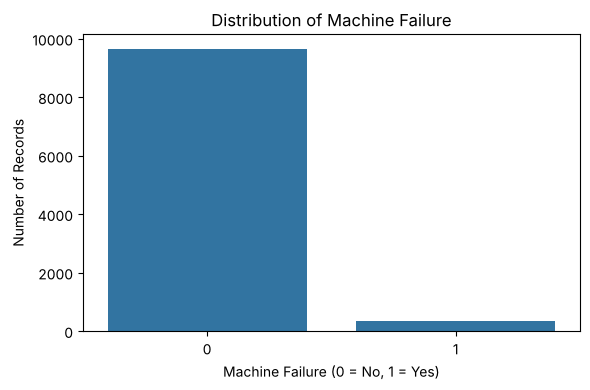

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

## Analyze feature relationships

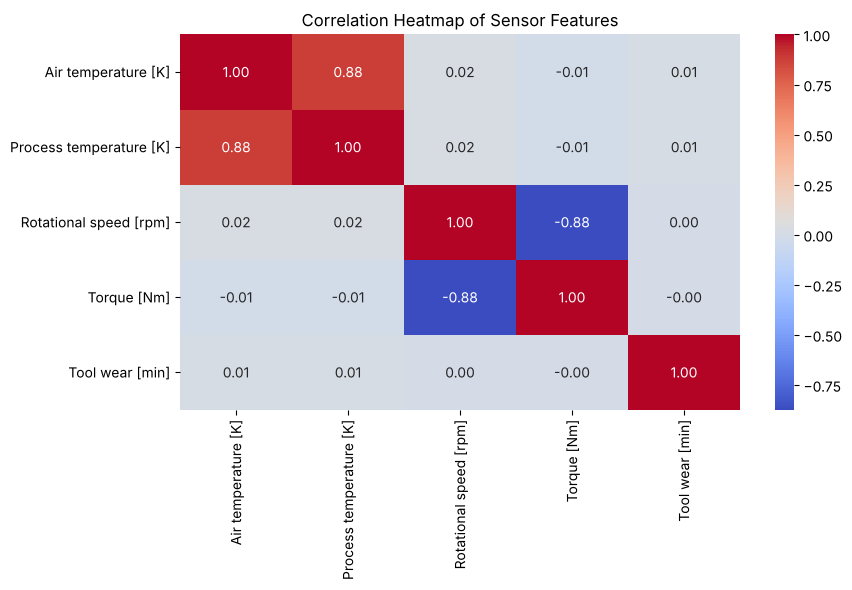

In [7]:
plt.figure(figsize=(9, 6))

correlation = X.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Sensor Features")
plt.tight_layout()
plt.show()

## Split the dataset into training and testing sets

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 8000
Testing records: 2000


## Standardize the features

In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data after scaling:")
print(X_train_scaled[:5])

Training data after scaling:
[[ 0.99891359  0.60428162 -0.46060741  0.71830476 -0.84399726]
 [-1.50519408 -1.15325984 -0.77557391  0.63845583  0.38226308]
 [ 0.49809206  1.07746586 -1.00765448  0.5586069   0.46086951]
 [-0.55363316 -0.13929361 -0.70926517  1.62658635 -0.37235867]
 [-1.45511192 -1.01806434  1.07001923 -1.12820177 -0.90688241]]


## Apply Principal Component Analysis (PCA)

In [10]:
pca_full = PCA()
pca_full.fit(X_train_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

print("Explained variance ratio:")
print(pca_full.explained_variance_ratio_)

print("\nCumulative explained variance:")
print(cumulative_variance)

n_components = np.searchsorted(
    cumulative_variance, 0.95
) + 1

print("\nComponents selected:", n_components)
print(
    "Variance retained:",
    round(cumulative_variance[n_components - 1] * 100, 2),
    "%"
)

Explained variance ratio:
[0.38209268 0.36802619 0.19993699 0.02547242 0.02447171]

Cumulative explained variance:
[0.38209268 0.75011887 0.95005586 0.97552829 1.        ]

Components selected: 3
Variance retained: 95.01 %


## Plot the explained variance

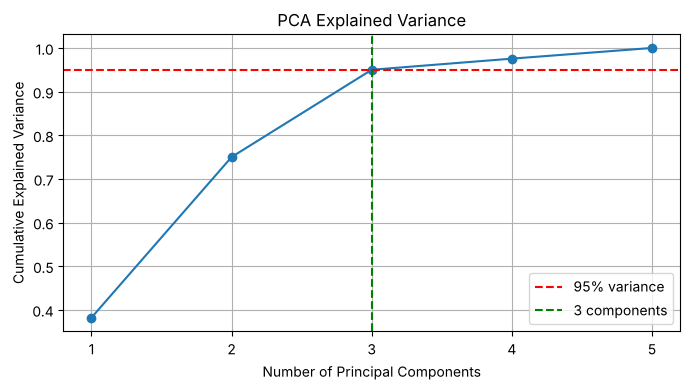

In [11]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    color="red",
    linestyle="--",
    label="95% variance"
)

plt.axvline(
    x=n_components,
    color="green",
    linestyle="--",
    label=f"{n_components} components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Transform the data using PCA

In [12]:
pca = PCA(n_components=n_components)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original training shape:", X_train_scaled.shape)
print("PCA training shape:", X_train_pca.shape)

print("Original testing shape:", X_test_scaled.shape)
print("PCA testing shape:", X_test_pca.shape)

Original training shape: (8000, 5)
PCA training shape: (8000, 3)
Original testing shape: (2000, 5)
PCA testing shape: (2000, 3)


## Train the Random Forest models (baseline)

In [13]:
# Model 1: Random Forest using original features
rf_original = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_original.fit(X_train_scaled, y_train)

# Model 2: Random Forest using PCA features
rf_pca = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_pca.fit(X_train_pca, y_train)

print("Both Random Forest models trained successfully.")

Both Random Forest models trained successfully.


## Evaluate the baseline models

In [14]:
# Generate predictions
y_pred_original = rf_original.predict(X_test_scaled)
y_pred_pca = rf_pca.predict(X_test_pca)

def evaluate_model(y_true, y_pred, model_name):
    print(f"\n--- {model_name} ---")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1-score :", round(f1_score(y_true, y_pred, zero_division=0), 4))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

evaluate_model(y_test, y_pred_original, "Random Forest with Original Features")
evaluate_model(y_test, y_pred_pca, "Random Forest with PCA Features")


--- Random Forest with Original Features ---
Accuracy : 0.982
Precision: 0.7424
Recall   : 0.7206
F1-score : 0.7313

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.74      0.72      0.73        68

    accuracy                           0.98      2000
   macro avg       0.87      0.86      0.86      2000
weighted avg       0.98      0.98      0.98      2000


--- Random Forest with PCA Features ---
Accuracy : 0.968
Precision: 0.5357
Recall   : 0.4412
F1-score : 0.4839

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1932
           1       0.54      0.44      0.48        68

    accuracy                           0.97      2000
   macro avg       0.76      0.71      0.73      2000
weighted avg       0.97      0.97      0.97      2000



## Display the baseline confusion matrices

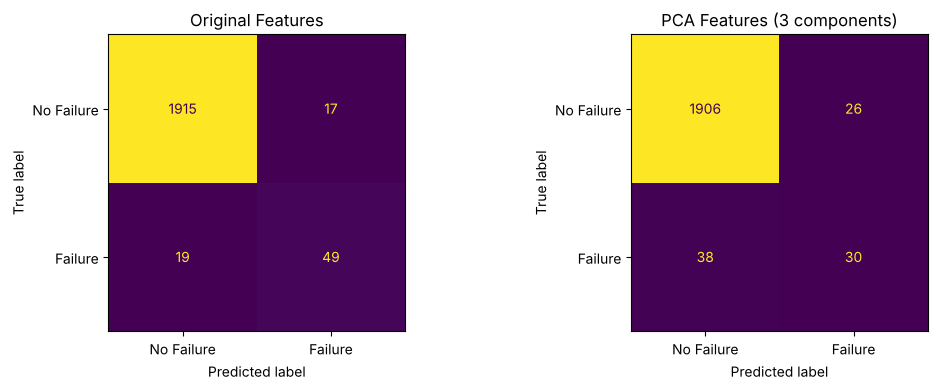

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_original,
    display_labels=["No Failure", "Failure"],
    ax=axes[0], colorbar=False
)
axes[0].set_title("Original Features")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_pca,
    display_labels=["No Failure", "Failure"],
    ax=axes[1], colorbar=False
)
axes[1].set_title("PCA Features (3 components)")

plt.tight_layout()
plt.show()

# PART B – IMPROVING THE MODEL
## Why accuracy alone is misleading
Only 3.4 % of the machines fail. A "model" that **always** answers *No Failure* would already be about 96.6 % accurate
while catching **zero** failures. So we also check **recall** (how many real failures are caught) and **balanced accuracy**.

In [16]:
baseline_accuracy = (y_test == 0).mean()
print("Accuracy of always predicting 'No Failure':", round(baseline_accuracy * 100, 2), "%")
print("Failures caught by that rule              : 0 of", int(y_test.sum()))

print("\nBaseline Random Forest (PCA) accuracy      :", round(accuracy_score(y_test, y_pred_pca) * 100, 2), "%")
print("Failures caught by baseline PCA model      :",
      int(((y_pred_pca == 1) & (y_test == 1)).sum()), "of", int(y_test.sum()))

Accuracy of always predicting 'No Failure': 96.6 %
Failures caught by that rule              : 0 of 68

Baseline Random Forest (PCA) accuracy      : 96.8 %
Failures caught by baseline PCA model      : 30 of 68


## Step 1 – Encode the categorical variable (machine Type)
`Type` is the product quality variant: **L** (low), **M** (medium), **H** (high). It was not used in the baseline.
It is converted to numbers with ordinal encoding because the three grades have a natural order.

In [17]:
type_mapping = {"L": 0, "M": 1, "H": 2}
df["Type_code"] = df["Type"].map(type_mapping)

print(df[["Type", "Type_code"]].drop_duplicates().sort_values("Type_code").to_string(index=False))
print("\nRecords per type:")
print(df["Type"].value_counts())

Type  Type_code
   L          0
   M          1
   H          2

Records per type:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


## Step 2 – Feature engineering (physics-based features)
The dataset documentation describes how the main failures occur. Three new features express these directly:

| New feature | Formula | Failure it relates to |
|---|---|---|
| Temperature difference [K] | process temperature − air temperature | heat-dissipation failure |
| Power [W] | torque × rotational speed × 2π / 60 | power failure |
| Strain [min·Nm] | tool wear × torque | overstrain failure |

In [18]:
def add_engineered_features(data):
    data = data.copy()
    data["Temperature difference [K]"] = data["Process temperature [K]"] - data["Air temperature [K]"]
    data["Power [W]"] = data["Torque [Nm]"] * data["Rotational speed [rpm]"] * 2 * np.pi / 60
    data["Strain [min*Nm]"] = data["Tool wear [min]"] * data["Torque [Nm]"]
    return data

df = add_engineered_features(df)

improved_features = features + [
    "Type_code",
    "Temperature difference [K]",
    "Power [W]",
    "Strain [min*Nm]"
]

print("Number of features now:", len(improved_features))
display(df[improved_features].describe().round(2))

Number of features now: 9


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_code,Temperature difference [K],Power [W],Strain [min*Nm]
count,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95,0.50,10.0,6279.74,4314.66
std,2.0,1.48,179.28,9.97,63.65,0.67,1.0,1067.42,2826.57
min,295.3,305.70,1168.00,3.80,0.00,0.00,7.6,1148.44,0.00
25%,298.3,308.80,1423.00,33.20,53.00,0.00,9.3,5561.18,1963.65
50%,300.1,310.10,1503.00,40.10,108.00,0.00,9.8,6271.03,4012.95
75%,301.5,311.10,1612.00,46.80,162.00,1.00,11.0,7003.00,6279.00
max,304.5,313.80,2886.00,76.60,253.00,2.00,12.1,10469.92,16497.00


## Step 3 – Outlier check (IQR rule)
A value is an outlier if it lies below Q1 − 1.5·IQR or above Q3 + 1.5·IQR.

In [19]:
numeric_cols = [c for c in improved_features if c != "Type_code"]
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (df[numeric_cols] < Q1 - 1.5 * IQR) | (df[numeric_cols] > Q3 + 1.5 * IQR)

outlier_table = pd.DataFrame({
    "Outliers": outlier_mask.sum(),
    "Failure rate among outliers (%)": [
        round(df.loc[outlier_mask[c], target].mean() * 100, 1) if outlier_mask[c].any() else 0
        for c in numeric_cols
    ]
})
display(outlier_table)
print("Overall failure rate (%):", round(df[target].mean() * 100, 1))

,Outliers,Failure rate among outliers (%)
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],418,8.4
Torque [Nm],69,89.9
Tool wear [min],0,0.0
Temperature difference [K],0,0.0
Power [W],60,100.0
Strain [min*Nm],20,100.0


Overall failure rate (%): 3.4


**Decision:** the outliers are real operating conditions (very high torque, very low speed, high strain), and machines in these
ranges fail far more often than average. Removing them would remove the failures we want to predict, so they are **kept**.
StandardScaler and PCA are then applied as usual.

## Step 4 – Correlation of the improved feature set

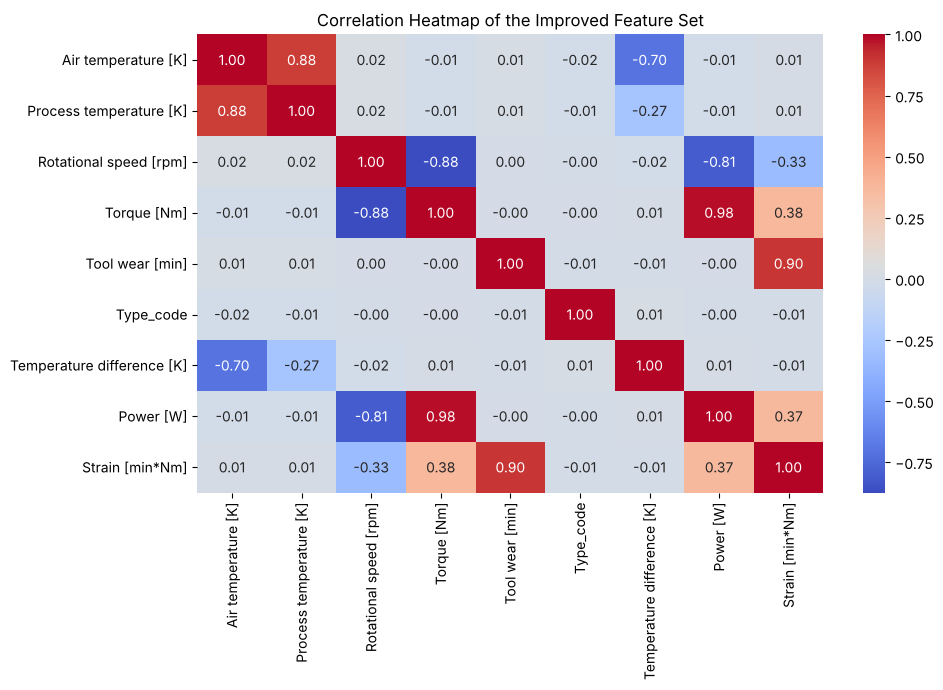

In [20]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[improved_features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of the Improved Feature Set")
plt.tight_layout()
plt.show()

## Step 5 – Split and scale the improved feature set (same split as before)

In [21]:
X2 = df[improved_features]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.20, random_state=42, stratify=y
)

scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

print("Training records:", X2_train.shape[0], "| Testing records:", X2_test.shape[0])
print("Same test records as the baseline:", (X2_test.index == X_test.index).all())

Training records: 8000 | Testing records: 2000
Same test records as the baseline: True


## Step 6 – PCA on the improved feature set
With 9 features the 95 % rule removes too much failure information, so we keep the components that hold **99 %** of the variance.

In [22]:
pca2_full = PCA().fit(X2_train_scaled)
cumulative_variance2 = np.cumsum(pca2_full.explained_variance_ratio_)

print("Explained variance ratio:")
print(np.round(pca2_full.explained_variance_ratio_, 4))
print("\nCumulative explained variance:")
print(np.round(cumulative_variance2, 4))

n_components2 = int(np.searchsorted(cumulative_variance2, 0.99) + 1)
print("\nComponents selected:", n_components2, "of", len(improved_features))
print("Variance retained:", round(cumulative_variance2[n_components2 - 1] * 100, 2), "%")

Explained variance ratio:
[0.3344 0.2515 0.1929 0.111  0.0819 0.0239 0.0031 0.0013 0.    ]

Cumulative explained variance:
[0.3344 0.5859 0.7788 0.8898 0.9717 0.9956 0.9987 1.     1.    ]

Components selected: 6 of 9
Variance retained: 99.56 %


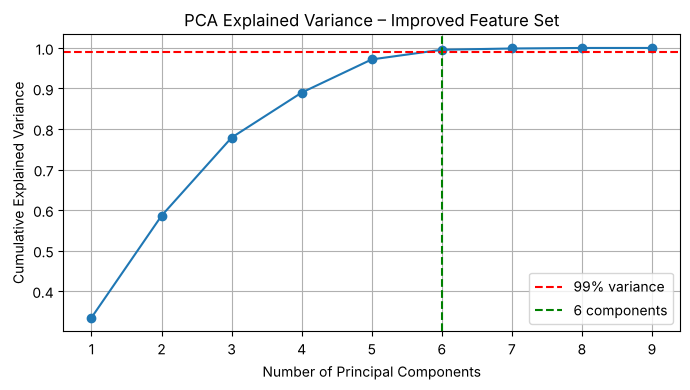

In [23]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumulative_variance2) + 1), cumulative_variance2, marker="o")
plt.axhline(y=0.99, color="red", linestyle="--", label="99% variance")
plt.axvline(x=n_components2, color="green", linestyle="--", label=f"{n_components2} components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance – Improved Feature Set")
plt.xticks(range(1, len(cumulative_variance2) + 1))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Step 7 – Choose the classifier with 5-fold cross-validation
Two classifiers are compared with 5-fold cross-validation on the **training set only**, each inside a pipeline
(scaler → PCA → classifier): a Random Forest and a **Support Vector Machine (RBF kernel)**, both with default settings.
The SVM is then tuned (C and gamma) with a grid search, because SVMs depend strongly on these two parameters.
The model with the best cross-validation accuracy is kept.

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidates = {
    "Random Forest (PCA)": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
    "SVM - RBF kernel (PCA)": SVC(kernel="rbf", random_state=42),
}

cv_rows = []
for name, clf in candidates.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=n_components2)), ("model", clf)])
    scores = cross_val_score(pipe, X2_train, y2_train, cv=cv, scoring="accuracy")
    cv_rows.append({"Model": name, "CV accuracy (%)": round(scores.mean() * 100, 2), "Std (%)": round(scores.std() * 100, 2)})

display(pd.DataFrame(cv_rows))

,Model,CV accuracy (%),Std (%)
0,Random Forest (PCA),98.05,0.46
1,SVM - RBF kernel (PCA),97.62,0.11


In [25]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=n_components2)),
    ("model", SVC(kernel="rbf", probability=True, random_state=42))
])

param_grid = {
    "model__C": [1, 10, 100, 300],
    "model__gamma": ["scale", 0.05, 0.2]
}

grid = GridSearchCV(svm_pipeline, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X2_train, y2_train)

best_model = grid.best_estimator_
print("Best parameters      :", grid.best_params_)
print("Best CV accuracy (%) :", round(grid.best_score_ * 100, 2))

Best parameters      : {'model__C': 300, 'model__gamma': 0.05}
Best CV accuracy (%) : 98.46


## Step 8 – Evaluate the improved model on the test set

In [26]:
y_pred_improved = best_model.predict(X2_test)

evaluate_model(y2_test, y_pred_improved, "Improved model: SVM with PCA features")

improved_accuracy = accuracy_score(y2_test, y_pred_improved)
print("Accuracy requirement (>= 94 %):", "MET" if improved_accuracy >= 0.94 else "NOT MET")


--- Improved model: SVM with PCA features ---
Accuracy : 0.9835
Precision: 0.807
Recall   : 0.6765
F1-score : 0.736

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.81      0.68      0.74        68

    accuracy                           0.98      2000
   macro avg       0.90      0.84      0.86      2000
weighted avg       0.98      0.98      0.98      2000

Accuracy requirement (>= 94 %): MET


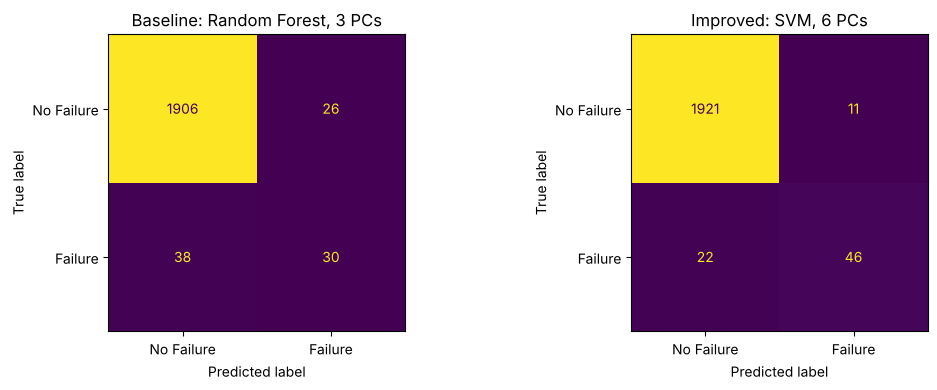

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_pca, display_labels=["No Failure", "Failure"], ax=axes[0], colorbar=False
)
axes[0].set_title("Baseline: Random Forest, 3 PCs")

ConfusionMatrixDisplay.from_predictions(
    y2_test, y_pred_improved, display_labels=["No Failure", "Failure"], ax=axes[1], colorbar=False
)
axes[1].set_title(f"Improved: SVM, {n_components2} PCs")

plt.tight_layout()
plt.show()

## Step 9 – Compare all models

In [28]:
from sklearn.metrics import balanced_accuracy_score

always_no = np.zeros(len(y_test), dtype=int)

def metrics_row(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Balanced accuracy (%)": round(balanced_accuracy_score(y_true, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_true, y_pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_true, y_pred, zero_division=0) * 100, 2),
        "F1-score (%)": round(f1_score(y_true, y_pred, zero_division=0) * 100, 2),
    }

comparison = pd.DataFrame([
    metrics_row("Always 'No Failure' (reference)", y_test, always_no),
    metrics_row("Baseline RF - 5 original features", y_test, y_pred_original),
    metrics_row(f"Baseline RF - PCA ({n_components} PCs)", y_test, y_pred_pca),
    metrics_row(f"Improved SVM - PCA ({n_components2} PCs)", y2_test, y_pred_improved),
])
display(comparison)

,Model,Accuracy (%),Balanced accuracy (%),Precision (%),Recall (%),F1-score (%)
0,Always 'No Failure' (reference),96.60,50.00,0.00,0.00,0.00
1,Baseline RF - 5 original features,98.20,85.59,74.24,72.06,73.13
2,Baseline RF - PCA (3 PCs),96.80,71.39,53.57,44.12,48.39
3,Improved SVM - PCA (6 PCs),98.35,83.54,80.70,67.65,73.60


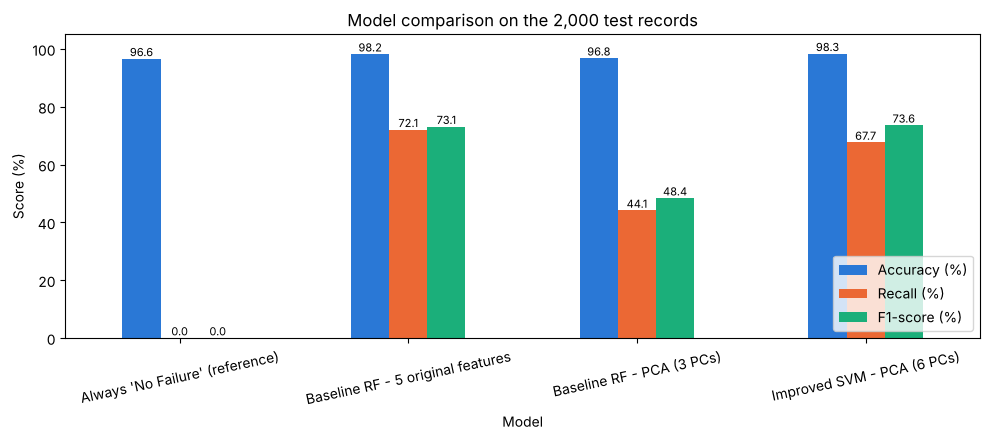

In [29]:
plot_df = comparison.set_index("Model")[["Accuracy (%)", "Recall (%)", "F1-score (%)"]]
ax = plot_df.plot(kind="bar", figsize=(10, 4.5), rot=12, color=["#2a78d6", "#eb6834", "#1baf7a"])
ax.set_ylabel("Score (%)")
ax.set_title("Model comparison on the 2,000 test records")
ax.set_ylim(0, 105)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Save the trained PCA model

In [30]:
import json

artifact_dir = Path("artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "pipeline": best_model,                      # scaler -> PCA -> SVM
    "features": improved_features,
    "base_features": features,
    "type_mapping": type_mapping,
    "n_components": n_components2,
    "variance_retained": float(cumulative_variance2[n_components2 - 1]),
}
model_path = artifact_dir / "pca_failure_model.joblib"
joblib.dump(model_bundle, model_path)

results = {
    "comparison": comparison.to_dict(orient="records"),
    "best_params": {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in grid.best_params_.items()},
    "best_cv_accuracy": float(grid.best_score_),
    "cv_comparison": cv_rows,
    "confusion_matrix": [[int(v) for v in row] for row in
                         pd.crosstab(y2_test, y_pred_improved).reindex(index=[0, 1], columns=[0, 1], fill_value=0).values],
    "n_components": n_components2,
    "n_features": len(improved_features),
    "variance_retained": float(cumulative_variance2[n_components2 - 1]),
    "explained_variance_ratio": [float(v) for v in pca2_full.explained_variance_ratio_],
    "test_records": int(len(y2_test)),
}
with open(artifact_dir / "model_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Model saved to  :", model_path)
print("Results saved to:", artifact_dir / "model_results.json")

Model saved to  : artifacts/pca_failure_model.joblib
Results saved to: artifacts/model_results.json


## Test the saved model with new sensor readings

In [31]:
loaded_bundle = joblib.load(model_path)

# Example machines: Type, Air temp, Process temp, Speed, Torque, Tool wear
examples = pd.DataFrame([
    ["L", 303.7, 312.4, 1513, 40.1, 135],
    ["L", 302.6, 310.4, 1359, 57.2, 67],
    ["L", 298.9, 310.2, 2737, 8.8, 142],
    ["L", 299.1, 310.2, 1317, 54.8, 231],
], columns=["Type"] + loaded_bundle["base_features"])

new_data = add_engineered_features(examples)
new_data["Type_code"] = new_data["Type"].map(loaded_bundle["type_mapping"])

predictions = loaded_bundle["pipeline"].predict(new_data[loaded_bundle["features"]])
probabilities = loaded_bundle["pipeline"].predict_proba(new_data[loaded_bundle["features"]])[:, 1]

examples["Prediction"] = np.where(predictions == 1, "Failure", "No Failure")
examples["Failure probability (%)"] = np.round(probabilities * 100, 1)
display(examples)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Prediction,Failure probability (%)
0,L,303.7,312.4,1513,40.1,135,No Failure,0.2
1,L,302.6,310.4,1359,57.2,67,Failure,86.8
2,L,298.9,310.2,2737,8.8,142,Failure,100.0
3,L,299.1,310.2,1317,54.8,231,Failure,100.0
